In [1]:
# ============================================================================
# 1 — Model definition + constants
# ===========================================================================
import numpy as np, csv, os
from scipy.integrate import solve_ivp
from scipy.signal import savgol_filter
from scipy.optimize import least_squares
from scipy.stats import mannwhitneyu
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

PIP_Index = 10   # PIP3 is species #10 in the state vector

def erika_model(t, y, k_bind_A, k_unbind_A, k_bind_B, k_unbind_B, k_phos,
                k_on_S, k_off_S, k_on_PI3K, k_off_PI3K, k_cat_pi3k, Km_pip2,
                k_on_SHIP1, k_off_SHIP1, k_cat_SHIP1, Km_PIP3):
    FcR_A, FcR_Ab_A, FcRp_A, FcR_B, FcR_Ab_B, FcRp_B, \
        S, PI3K, SHIP1, PIP2, PIP3, PIP2_34, Ab_A, Ab_B = y

    # Activating receptor arm (A)
    dFcR_A_dt    = -k_bind_A * Ab_A * FcR_A + k_unbind_A * FcR_Ab_A
    dFcR_Ab_A_dt = -dFcR_A_dt - k_phos * FcR_Ab_A
    dFcRp_A_dt   =  k_phos * FcR_Ab_A
    dAb_A_dt     =  dFcR_A_dt

    # Inhibitory receptor arm (B)
    dFcR_B_dt    = -k_bind_B * Ab_B * FcR_B + k_unbind_B * FcR_Ab_B
    dFcR_Ab_B_dt = -dFcR_B_dt - k_phos * FcR_Ab_B
    dFcRp_B_dt   =  k_phos * FcR_Ab_B
    dAb_B_dt     =  dFcR_B_dt

    # Downstream messengers
    dS_dt     = k_on_S * FcRp_A     - k_off_S * S
    dPI3K_dt  = k_on_PI3K * S       - k_off_PI3K * PI3K
    dSHIP1_dt = k_on_SHIP1 * FcRp_B - k_off_SHIP1 * SHIP1

    # Lipids
    pip3_gen  = k_cat_pi3k  * PI3K  * (PIP2 / (Km_pip2 + PIP2))
    pip3_cons = k_cat_SHIP1 * SHIP1 * (PIP3 / (Km_PIP3 + PIP3))

    return [dFcR_A_dt, dFcR_Ab_A_dt, dFcRp_A_dt,
            dFcR_B_dt, dFcR_Ab_B_dt, dFcRp_B_dt,
            dS_dt, dPI3K_dt, dSHIP1_dt,
            -pip3_gen, pip3_gen - pip3_cons, pip3_cons,
            dAb_A_dt, dAb_B_dt]

# ---- Constants -------------------------------------------------------------
C_ref    = 1e-6
Ab_molar = 30e-9
KD_IIA, KD_IIB = 0.98e-6, 2.3e-6
Ab_A0 = Ab_molar / C_ref
Ab_B0 = Ab_molar * (KD_IIA / KD_IIB) / C_ref

y0 = [1.0, 0, 0,  1.0, 0, 0,  0, 0, 0,  3.0, 0, 0,  Ab_A0, Ab_B0]
t_data = np.linspace(0, 10*60, 30)

PNAMES = ['k_bind_A', 'k_unbind_A', 'k_bind_B', 'k_unbind_B', 'k_phos',
          'k_on_S', 'k_off_S', 'k_on_PI3K', 'k_off_PI3K', 'k_cat_pi3k',
          'Km_pip2', 'k_on_SHIP1', 'k_off_SHIP1', 'k_cat_SHIP1', 'Km_PIP3']

params_g = np.array([
    6.51e3 * C_ref, 4.71e-3, 3.8e5 * C_ref, 0.88, 0.15,
    1.5e5  * C_ref, 0.13,    3.34e6 * C_ref, 1.002, 0.975,
    1.80,           1.05e6 * C_ref, 0.29,    8.0,   94.0])

NP = len(params_g)            # 15
sigma = 0.02                  # cosmetic (see header note)
print('Section 1 complete: model + constants defined.')

Section 1 complete: model + constants defined.


IgG: 10 cells x 30 timepoints
IgG+DNA: 10 cells x 30 timepoints
Loaded cached fits from unified_fits_20000cap_zerofloor.npz

Convergence:
  IgG: all converged; nfev min/median/max = 347/866/6438
  IgG+DNA: all converged; nfev min/median/max = 178/616/1626


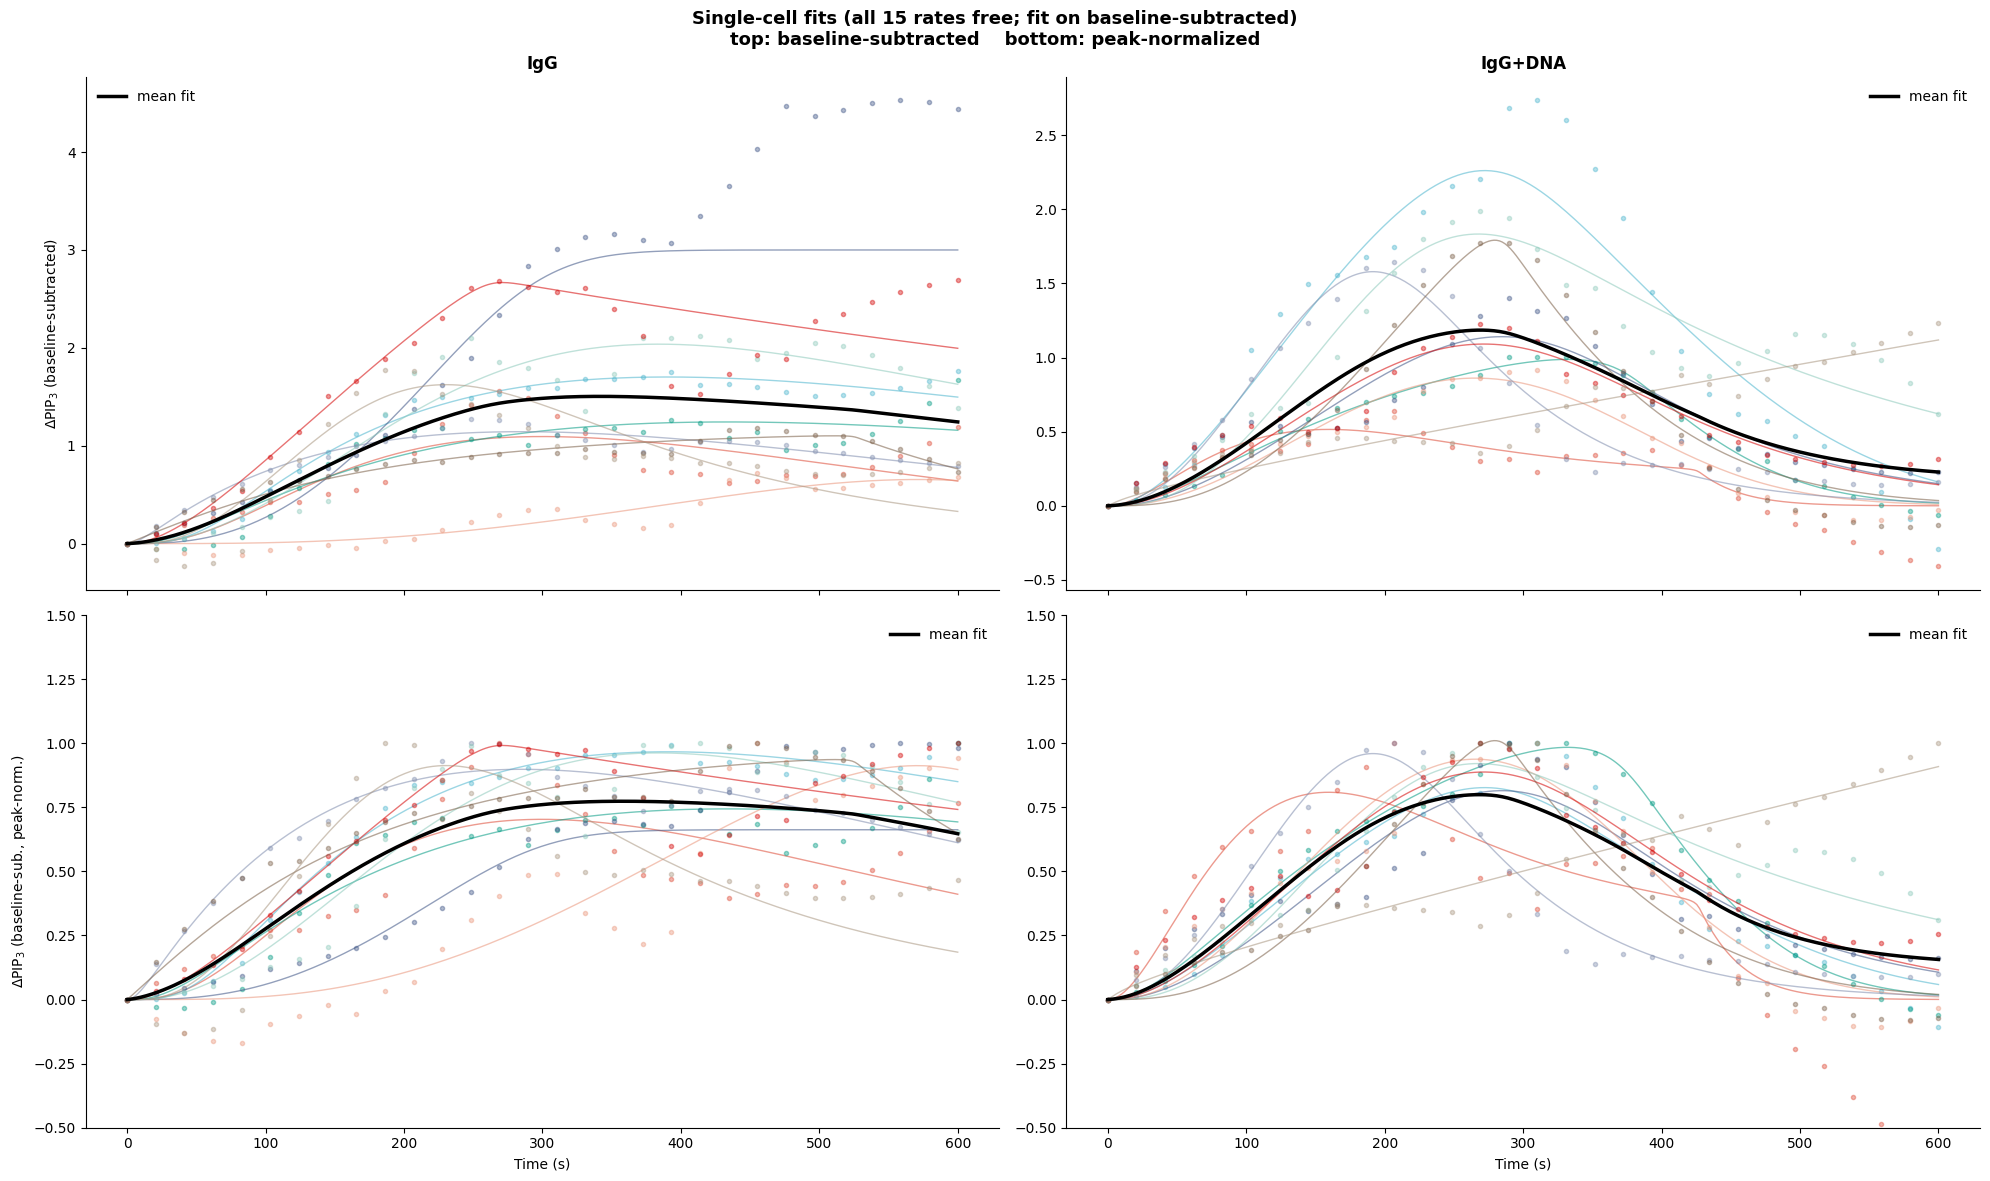

Saved: trace_fits_unified.png (baseline + peak-normalized)
Section 2 complete.


In [11]:
# ============================================================================
# 2 — Load data + single-cell fitting (cached) + trace figure
# ============================================================================
# Fitting is ALWAYS on baseline-subtracted data. sigma only rescales the Fisher
# matrix (cosmetic). All parameters share a lower bound of 0; the log
# transform in Section 4 uses np.maximum(..., 1e-30) to keep any collapsed
# value finite, and SUPP S1 flags fits that sit against a bound.
CONDITIONS = {'IgG': 'IgG.csv', 'IgG+DNA': 'IgG+DNA.csv'}
CACHE = 'unified_fits_20000cap_zerofloor.npz'    # stores params, nfev, status
MAX_NFEV = 20000

LOWER = np.zeros(NP)

def load_baseline_subtracted(path):
    raw = np.array(list(csv.reader(open(path, encoding='utf-8-sig'))),
                   dtype=np.double)
    smoothed = savgol_filter(raw, window_length=10, polyorder=2, axis=0)
    return smoothed - smoothed[0, :]

def fit_one_cell(trace, p0):
    def objective(params):
        sol = solve_ivp(erika_model, [t_data[0], t_data[-1]], y0,
                        method='Radau', t_eval=t_data, args=tuple(params),
                        rtol=1e-5, atol=1e-7)
        if sol.status != 0:
            return np.ones_like(trace) * 1e5
        return sol.y[PIP_Index] - trace
    r = least_squares(objective, p0, bounds=(LOWER, [1e6]*NP),
                      verbose=0, max_nfev=MAX_NFEV)
    return r.x, int(r.nfev), int(r.status)

# raw traces (only needed for the trace figure and for re-fitting)
data_bs = {}
for cond, path in CONDITIONS.items():
    if os.path.exists(path):
        data_bs[cond] = load_baseline_subtracted(path)
        print(f'{cond}: {data_bs[cond].shape[1]} cells x '
              f'{data_bs[cond].shape[0]} timepoints')
    else:
        print(f'{cond}: raw CSV "{path}" not found (fine if using the cache).')

# fitted parameters: load cache if present, else fit
if os.path.exists(CACHE):
    _c = np.load(CACHE, allow_pickle=True)
    params_fitted = {c: _c[f'{c}_params'].astype(np.float64) for c in CONDITIONS}
    nfev_fitted   = {c: _c[f'{c}_nfev'].astype(np.int64)     for c in CONDITIONS
                     if f'{c}_nfev' in _c.files}
    status_fitted = {c: _c[f'{c}_status'].astype(np.int64)   for c in CONDITIONS
                     if f'{c}_status' in _c.files}
    print(f'Loaded cached fits from {CACHE}')
else:
    params_fitted, nfev_fitted, status_fitted = {}, {}, {}
    for cond in CONDITIONS:
        traces = data_bs[cond]
        results = Parallel(n_jobs=-1)(
            delayed(fit_one_cell)(traces[:, j], params_g)
            for j in range(traces.shape[1]))
        params_fitted[cond] = np.array([r[0] for r in results])
        nfev_fitted[cond]   = np.array([r[1] for r in results])
        status_fitted[cond] = np.array([r[2] for r in results])
    np.savez(CACHE, **{f'{c}_params': params_fitted[c] for c in CONDITIONS},
                     **{f'{c}_nfev':   nfev_fitted[c]   for c in CONDITIONS},
                     **{f'{c}_status': status_fitted[c] for c in CONDITIONS})
    print(f'Saved fits -> {CACHE}')

cond_list = list(CONDITIONS.keys())

# ---- convergence report (status 0 = hit max_nfev; 1-4 = converged) ----
if status_fitted:
    print('\nConvergence:')
    for c in CONDITIONS:
        st, nf = status_fitted[c], nfev_fitted[c]
        n_trunc = int(np.sum(st == 0))
        note = f'{n_trunc} hit max_nfev' if n_trunc else 'all converged'
        print(f'  {c}: {note}; nfev min/median/max = '
              f'{nf.min()}/{int(np.median(nf))}/{nf.max()}')

# ---- colours ----
C_IgG = np.array([60, 84, 136]) / 265.0
C_DNA = np.array([220, 0, 0])   / 265.0
colormap = np.array([[230,75,53],[77,187,213],[0,160,135],[60,84,136],
                     [243,155,127],[132,145,180],[145,209,194],[220,0,0],
                     [126,97,72],[176,156,133]]) / 265.0

# ---- trace-fit figure (top: baseline-subtracted; bottom: peak-normalized) ----
if all(c in data_bs for c in CONDITIONS):
    t_fine = np.linspace(0, 10*60, 300)
    fig, axes = plt.subplots(2, 2, figsize=(20, 12), sharex=True)
    fig.suptitle('Single-cell fits (all 15 rates free; fit on baseline-subtracted)\n'
                 'top: baseline-subtracted    bottom: peak-normalized',
                 fontsize=13, fontweight='bold')
    for col, cond in enumerate(CONDITIONS):
        traces, P = data_bs[cond], params_fitted[cond]
        raw_curves, norm_curves = [], []
        for j in range(P.shape[0]):
            clr = colormap[j % len(colormap)]
            sol = solve_ivp(erika_model, [t_fine[0], t_fine[-1]], y0,
                            method='Radau', t_eval=t_fine,
                            args=tuple(P[j]), rtol=1e-5, atol=1e-7)
            fit = sol.y[PIP_Index]
            scale = traces[:, j].max()
            if scale <= 0:
                scale = 1.0
            axes[0, col].plot(t_data, traces[:, j], 'o', ms=3, color=clr, alpha=0.4)
            axes[0, col].plot(t_fine, fit, '-', color=clr, alpha=0.55, lw=1)
            raw_curves.append(fit)
            axes[1, col].plot(t_data, traces[:, j] / scale, 'o', ms=3, color=clr, alpha=0.4)
            axes[1, col].plot(t_fine, fit / scale, '-', color=clr, alpha=0.55, lw=1)
            norm_curves.append(fit / scale)
        axes[0, col].plot(t_fine, np.mean(raw_curves, axis=0), 'k-', lw=2.5, label='mean fit')
        axes[1, col].plot(t_fine, np.mean(norm_curves, axis=0), 'k-', lw=2.5, label='mean fit')
        axes[0, col].set_title(cond, fontweight='bold')
        axes[1, col].set_xlabel('Time (s)')
        axes[1, col].set_ylim(-0.5, 1.5)          # fixed scale for the normalized row
        for r in (0, 1):
            axes[r, col].legend(frameon=False)
            axes[r, col].spines[['top', 'right']].set_visible(False)
    axes[0, 0].set_ylabel(r'$\Delta$PIP$_3$ (baseline-subtracted)')
    axes[1, 0].set_ylabel(r'$\Delta$PIP$_3$ (baseline-sub., peak-norm.)')
    plt.tight_layout()
    plt.savefig('trace_fits_unified.png', dpi=300, bbox_inches='tight')
    plt.savefig('trace_fits_unified.pdf', bbox_inches='tight')  # <-- new line
    plt.show()
    print('Saved: trace_fits_unified.png (baseline + peak-normalized)')
print('Section 2 complete.')

Fisher matrix built. condition number = 1.26e+17, n_stiff = 10  (n_stiff is decided inside fisher() from the spectral gap)

FISHER EIGENVECTOR MATRIX  (columns EV1..EV15; first 10 are stiff)
  param           EV1    EV2    EV3    EV4    EV5    EV6    EV7    EV8    EV9   EV10   EV11   EV12   EV13   EV14   EV15
  ---------------------------------------------------------------------------------------------------------------------
  k_bind_A      -0.09   0.31  -0.55   0.07  -0.22   0.54   0.39  -0.23   0.19  -0.04  -0.03  -0.02   0.00  -0.00   0.00
  k_unbind_A     0.00  -0.01   0.01   0.02  -0.00  -0.02  -0.03   0.04   0.01  -0.01  -0.80  -0.59   0.03  -0.03   0.00
  k_bind_B      -0.00  -0.01  -0.03  -0.04   0.51  -0.13   0.36  -0.28  -0.22  -0.06   0.38  -0.55   0.07  -0.04  -0.00
  k_unbind_B     0.00   0.01   0.03   0.03  -0.46   0.11  -0.33   0.26   0.21   0.08   0.46  -0.58   0.08  -0.04  -0.00
  k_phos        -0.02   0.04  -0.35   0.55   0.36  -0.22   0.07   0.55   0.29   0.05   0.

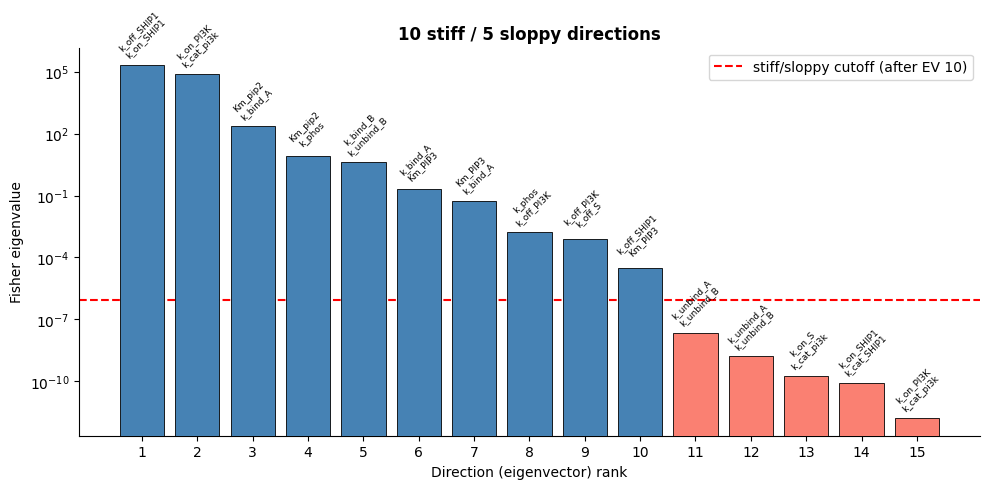


Saved: eigenvalue_spectrum_cutoff.png
Section 3 complete: FIM + eigenvector matrix + stiff/sloppy split.


In [4]:
# ============================================================================
# 3 — Fisher matrix + eigenvector matrix + stiff/sloppy split
#   (n_stiff is decided inside fisher() from the spectral gap; the printout,
#    full eigenvector matrix, and bar plot are all here in one cell.)
# ============================================================================
def sim_pip3(p_vec, y0_vec=y0):
    """Return the PIP3 curve for a parameter set."""
    sol = solve_ivp(erika_model, [t_data[0], t_data[-1]], y0_vec,
                    method='Radau', t_eval=t_data, args=tuple(p_vec),
                    rtol=1e-8, atol=1e-10)
    return sol.y[PIP_Index]

def fisher(p_anchor, fd_step=0.01):
    """
    Build the Fisher matrix at a chosen parameter point ("anchor") and return
    its eigen-decomposition plus the stiff/sloppy split.
      evals   : eigenvalues, largest first (how well-determined each direction is)
      evecs   : matching eigenvectors as columns (the directions themselves)
      n_stiff : number of stiff directions (from the biggest jump in the spectrum)
      gap_idx : index of that biggest jump
    """
    base = sim_pip3(p_anchor)
    J = np.zeros((len(t_data), NP))
    for i in range(NP):                       # one column per parameter
        pp = p_anchor.copy()
        pp[i] *= (1 + fd_step)
        J[:, i] = (sim_pip3(pp) - base) / (p_anchor[i] * fd_step)
    J_log = J * p_anchor[np.newaxis, :]       # work in log-parameter space
    F = J_log.T @ J_log / sigma**2
    evals, evecs = np.linalg.eigh(F)
    evals, evecs = evals[::-1], evecs[:, ::-1]     # largest first
    log_gaps = np.abs(np.diff(np.log10(np.maximum(evals, 1e-30))))
    gap_idx = int(np.argmax(log_gaps))
    return {'evals': evals, 'evecs': evecs,
            'n_stiff': gap_idx + 1, 'gap_idx': gap_idx}

# Anchor the whole analysis at the literature parameters (a SINGLE shared anchor
# used for BOTH conditions, so the eigenvector directions are identical for each).
fim = fisher(params_g)
evals, evecs = fim['evals'], fim['evecs']
n_stiff, gap_idx = fim['n_stiff'], fim['gap_idx']
V_stiff = evecs[:, :n_stiff]
log_p_nom = np.log(params_g)

cond_number = evals[0] / max(evals[-1], 1e-30)
print(f'Fisher matrix built. condition number = {cond_number:.2e}, '
      f'n_stiff = {n_stiff}  (n_stiff is decided inside fisher() from the '
      f'spectral gap)')

# ---- full eigenvector matrix (rows = parameters, cols = EV1..EV15) ----------
# Entry [r, c] = weight of parameter r in eigenvector c. Bottom row = log10 of
# each eigenvalue. Columns 1..n_stiff are the stiff (identifiable) directions.
_lev = np.log10(np.maximum(evals, 1e-30))
print('\nFISHER EIGENVECTOR MATRIX  (columns EV1..EV{0}; first {1} are stiff)'.format(NP, n_stiff))
print('  ' + f'{"param":<12}' + ''.join(f'{"EV"+str(c+1):>7}' for c in range(NP)))
print('  ' + '-'*(12 + 7*NP))
for r, pn in enumerate(PNAMES):
    print('  ' + f'{pn:<12}' + ''.join(f'{evecs[r, c]:>7.2f}' for c in range(NP)))
print('  ' + '-'*(12 + 7*NP))
print('  ' + f'{"log10 eval":<12}' + ''.join(f'{_lev[c]:>7.1f}' for c in range(NP)))

# ---- stiff / sloppy summary ---------------------
print(f'\n  => stiff (well-determined): directions 1-{n_stiff}')
print(f'     sloppy (poorly determined): directions {n_stiff+1}-{NP}')
n_stiff_1e8 = int(np.sum(evals > evals[0] * 1e-8))
if n_stiff_1e8 != n_stiff:
    print(f'  (Heads-up: a fixed 1e-8 cutoff would say {n_stiff_1e8} stiff, '
          f'not {n_stiff}. The cutoff is somewhat arbitrary.)')

# ---- eigenvalue bar plot ---------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
colors_ev = ['steelblue' if i < n_stiff else 'salmon' for i in range(NP)]
ax.bar(range(1, NP+1), np.maximum(evals, 1e-30), color=colors_ev,
       edgecolor='k', lw=0.6, zorder=3)
ax.set_yscale('log')
ax.axhline(np.sqrt(max(evals[gap_idx]*evals[gap_idx+1], 1e-60)), color='red',
           ls='--', lw=1.5, label=f'stiff/sloppy cutoff (after EV {n_stiff})')
for i in range(NP):
    top = np.argsort(-np.abs(evecs[:, i]))[:2]
    ax.text(i+1, max(evals[i], 1e-30)*1.8, '\n'.join(PNAMES[j] for j in top),
            ha='center', va='bottom', fontsize=6.5, rotation=45)
ax.set_xlabel('Direction (eigenvector) rank'); ax.set_ylabel('Fisher eigenvalue')
ax.set_title(f'{n_stiff} stiff / {NP-n_stiff} sloppy directions', fontweight='bold')
ax.set_xticks(range(1, NP+1)); ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('eigenvalue_spectrum_cutoff.png', dpi=300,
                                bbox_inches='tight'); plt.show()
print('\nSaved: eigenvalue_spectrum_cutoff.png')
print('Section 3 complete: FIM + eigenvector matrix + stiff/sloppy split.')


COMPOSITE ANALYSIS  (each knob projected onto the 10 stiff directions)
  composite            parameters                                                      %stiff >=75%  p(2-sided)  p(1-sided)  sig  aligns with (top stiff EVs)
  ----------------------------------------------------------------------------------------------------------------------------------------------------------
  act_Syk_recruit      k_on_S / k_off_S                                                 66.7%     X      0.2413      0.2413       EV2(+0.54), EV4(-0.37)
  act_PI3K_recruit     k_on_PI3K / k_off_PI3K                                           66.7%     X      0.4727      0.4727       EV2(+0.57), EV9(-0.51)
  act_PI3K_catalysis   k_cat_pi3k / Km_pip2                                             66.7%     X      0.0312      0.0312    *  EV4(+0.45), EV2(+0.43)
  act_Syk_PI3K_relay   k_on_S*k_on_PI3K / k_off_S*k_off_PI3K                            83.3%     ✓      0.9097      0.9097       EV2(+0.79), EV4(-0.25)
 

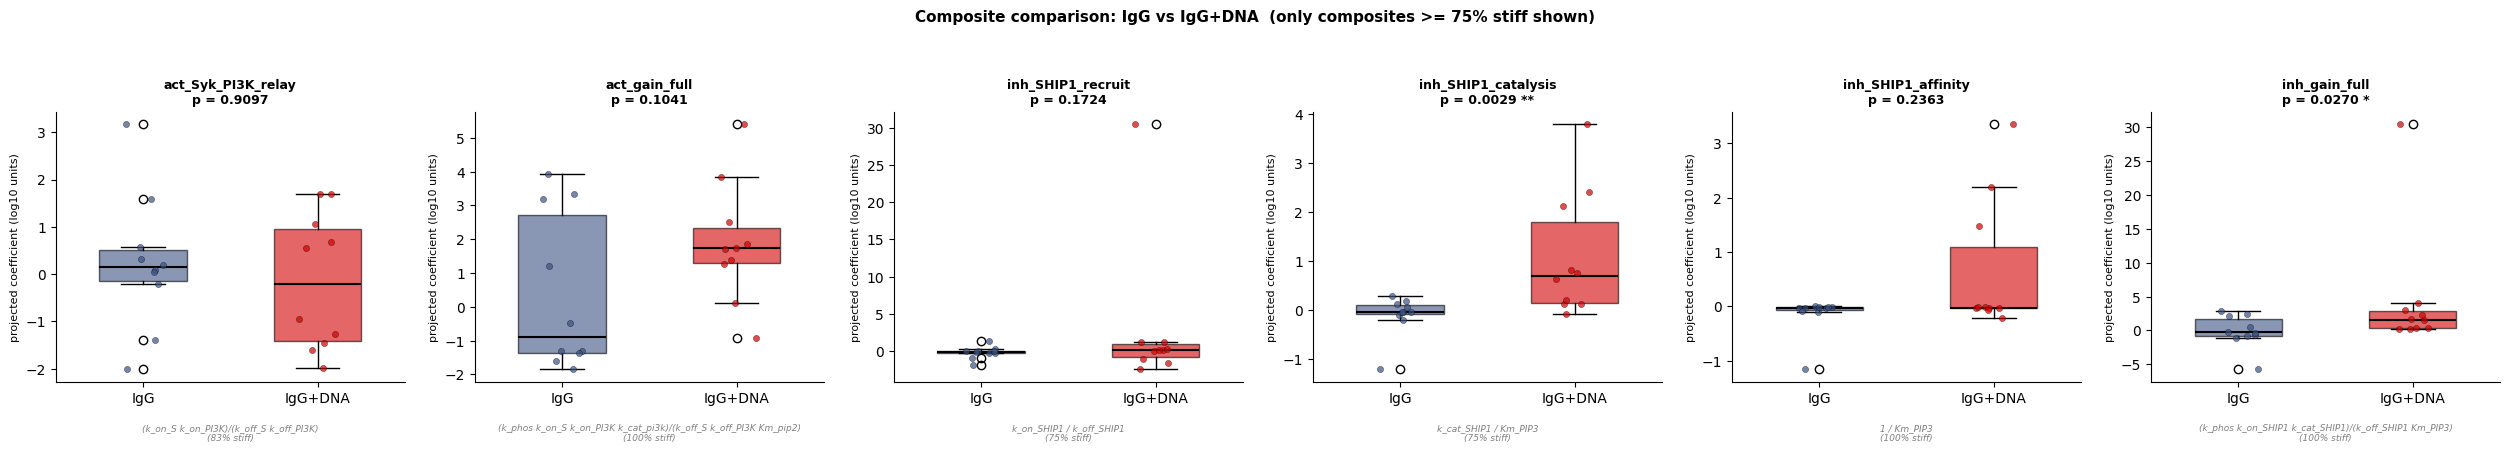


Saved: substage_boxplots.png
Section 4 complete.


In [13]:
# ============================================================================
# SECTION 4 — Composite analysis  (the eigenvector-based IgG vs IgG+DNA test)
# ============================================================================
def _dir(pos, neg):
    a = np.zeros(NP)
    for i in pos: a[i] = 1
    for i in neg: a[i] = -1
    return a

def dir_to_expr(a):
    """Human-readable 'num1*num2 / den1*den2' built from a composite's log_dir,
    so the table shows the actual parameters instead of an arbitrary name."""
    num = [PNAMES[i] for i in range(NP) if a[i] > 0]
    den = [PNAMES[i] for i in range(NP) if a[i] < 0]
    s = '*'.join(num) if num else '1'
    if den:
        s += ' / ' + '*'.join(den)
    return s

SUBSTAGE_COMPOSITES = {
    # activating arm
    'act_Syk_recruit':    {'eq': 'k_on_S / k_off_S',                       'log_dir': _dir([5],[6]),           'hypothesis': 'no difference', 'arm': 'activating'},
    'act_PI3K_recruit':   {'eq': 'k_on_PI3K / k_off_PI3K',                 'log_dir': _dir([7],[8]),           'hypothesis': 'no difference', 'arm': 'activating'},
    'act_PI3K_catalysis': {'eq': 'k_cat_pi3k / Km_pip2',                   'log_dir': _dir([9],[10]),          'hypothesis': 'no difference', 'arm': 'activating'},
    'act_Syk_PI3K_relay': {'eq': '(k_on_S k_on_PI3K)/(k_off_S k_off_PI3K)','log_dir': _dir([5,7],[6,8]),       'hypothesis': 'no difference', 'arm': 'activating'},
    'act_gain_full':      {'eq': '(k_phos k_on_S k_on_PI3K k_cat_pi3k)/(k_off_S k_off_PI3K Km_pip2)',
                                                                           'log_dir': _dir([4,5,7,9],[6,8,10]),'hypothesis': 'no difference', 'arm': 'activating'},
    # inhibitory arm
    'inh_SHIP1_recruit':  {'eq': 'k_on_SHIP1 / k_off_SHIP1',               'log_dir': _dir([11],[12]),         'hypothesis': 'DNA > IgG',     'arm': 'inhibitory'},
    'inh_SHIP1_catalysis':{'eq': 'k_cat_SHIP1 / Km_PIP3',                  'log_dir': _dir([13],[14]),         'hypothesis': 'DNA > IgG',     'arm': 'inhibitory'},
    'inh_SHIP1_Vmax':     {'eq': 'k_cat_SHIP1',                            'log_dir': _dir([13],[]),           'hypothesis': 'DNA > IgG',     'arm': 'inhibitory'},
    'inh_SHIP1_affinity': {'eq': '1 / Km_PIP3',                            'log_dir': _dir([],[14]),           'hypothesis': 'DNA > IgG',     'arm': 'inhibitory'},
    'inh_gain_full':      {'eq': '(k_phos k_on_SHIP1 k_cat_SHIP1)/(k_off_SHIP1 Km_PIP3)',
                                                                           'log_dir': _dir([4,11,13],[12,14]), 'hypothesis': 'DNA > IgG',     'arm': 'inhibitory'},
}

def safe_mwu(a, b):
    if np.allclose(a, b, rtol=1e-6) or np.std(np.concatenate([a, b])) < 1e-12:
        return 1.0
    return mannwhitneyu(a, b, alternative='two-sided').pvalue

def composite_pvalues(a_stiff, Dmap, hyp):
    """One- and two-sided p for a projected composite, given a per-cell log-delta map."""
    a_vals, b_vals = Dmap[cond_list[0]] @ a_stiff, Dmap[cond_list[1]] @ a_stiff
    p2 = safe_mwu(a_vals, b_vals)
    if hyp == 'DNA > IgG':
        p1 = mannwhitneyu(b_vals, a_vals, alternative='greater').pvalue
    elif hyp == 'DNA < IgG':
        p1 = mannwhitneyu(a_vals, b_vals, alternative='greater').pvalue
    else:
        p1 = p2
    return p2, p1, (p1 if hyp != 'no difference' else p2)

# distance of each cell's fitted params from the anchor, in log space (n_cells x 15)
D = {c: np.log(np.maximum(params_fitted[c], 1e-30)) - log_p_nom for c in CONDITIONS}
ev_coeffs = {c: D[c] @ evecs for c in CONDITIONS}   # used by SUPP S3

arm_order = ['activating', 'inhibitory', 'cross-arm']
ordered_names = sorted(SUBSTAGE_COMPOSITES,
                       key=lambda n: arm_order.index(SUBSTAGE_COMPOSITES[n]['arm']))

# each row: short name + the parameters the composite is made of (from log_dir)
w  = max(len(dir_to_expr(SUBSTAGE_COMPOSITES[n]['log_dir'])) for n in ordered_names)
wn = max(len(n) for n in ordered_names)
STIFF_CUT = 0.75          # composites at/above this are plotted; below get an X
_tblw = wn + 2 + w + 7 + 6 + 12 + 12 + 5 + 30
print('\n' + '='*_tblw)
print(f'COMPOSITE ANALYSIS  (each knob projected onto the {n_stiff} stiff directions)')
print('='*_tblw)
print(f'  {"composite":<{wn}}  {"parameters":<{w}}{"%stiff":>7}{">=75%":>6}{"p(2-sided)":>12}'
      f'{"p(1-sided)":>12}{"sig":>5}  aligns with (top stiff EVs)')
print('  ' + '-'*(_tblw - 2))

substage_proj = {}
for name in ordered_names:
    info = SUBSTAGE_COMPOSITES[name]
    a = info['log_dir']; norm_a = np.linalg.norm(a)
    a_stiff = V_stiff @ (V_stiff.T @ a)                     # keep only stiff part
    info['frac_stiff'] = (np.linalg.norm(a_stiff)/norm_a)**2 if norm_a else 0.0
    substage_proj[name] = {c: (D[c] @ a_stiff) / np.log(10) for c in CONDITIONS}  # log10 units

    ev_overlap = evecs.T @ (a / norm_a) if norm_a else np.zeros(NP)
    top_ev = np.argsort(-np.abs(ev_overlap[:n_stiff]))[:2]
    ev_ident = ', '.join(f'EV{e+1}({ev_overlap[e]:+.2f})' for e in top_ev)

    p2, p1, p_use = composite_pvalues(a_stiff, D, info['hypothesis'])
    info['p_two'], info['p_one'], info['p_use'] = p2, p1, p_use
    sig = '***' if p_use < 0.001 else '**' if p_use < 0.01 else '*' if p_use < 0.05 else ''
    mark = '✓' if round(info['frac_stiff']*100, 1) >= STIFF_CUT*100 else 'X'
    print(f'  {name:<{wn}}  {dir_to_expr(a):<{w}}{info["frac_stiff"]*100:>6.1f}%{mark:>6}'
          f'{p2:>12.4f}{p1:>12.4f}{sig:>5}  {ev_ident}')

# ---- boxplots: ONLY composites that pass the >=75% stiff cutoff, single row ----
all_plot = [n for n in ordered_names
            if round(SUBSTAGE_COMPOSITES[n]['frac_stiff']*100, 1) >= STIFF_CUT*100]
n_cols = max(len(all_plot), 1); n_rows = 1
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2*n_cols, 4.8), squeeze=False)
rng = np.random.default_rng(42)
for idx, name in enumerate(all_plot):
    ax = axes[0][idx]; info = SUBSTAGE_COMPOSITES[name]
    a_v, b_v = substage_proj[name][cond_list[0]], substage_proj[name][cond_list[1]]
    bp = ax.boxplot([a_v, b_v], widths=0.5, patch_artist=True,
                    tick_labels=cond_list, medianprops=dict(color='k', lw=1.5))
    bp['boxes'][0].set_facecolor(C_IgG); bp['boxes'][0].set_alpha(0.6)
    bp['boxes'][1].set_facecolor(C_DNA); bp['boxes'][1].set_alpha(0.6)
    for k, vals in enumerate([a_v, b_v]):
        ax.scatter(np.full_like(vals, k+1) + rng.uniform(-0.12, 0.12, len(vals)),
                   vals, c=[C_IgG if k == 0 else C_DNA], s=20, alpha=0.7,
                   edgecolors='k', linewidths=0.3, zorder=3)
    pv = info['p_use']
    star = ' ***' if pv < 0.001 else ' **' if pv < 0.01 else ' *' if pv < 0.05 else ''
    ax.set_title(f'{name}\np = {pv:.4f}{star}', fontsize=9, fontweight='bold')
    ax.text(0.5, -0.22, f'{info["eq"]}\n({info["frac_stiff"]*100:.0f}% stiff)',
            transform=ax.transAxes, ha='center', fontsize=6.5, style='italic', color='gray')
    ax.set_ylabel('projected coefficient (log10 units)', fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
for idx in range(len(all_plot), n_rows*n_cols):
    axes[idx // n_cols][idx % n_cols].set_visible(False)
fig.suptitle(f'Composite comparison: IgG vs IgG+DNA  '
             f'(only composites >= {STIFF_CUT*100:.0f}% stiff shown)',
             fontsize=11, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('substage_boxplots.png', dpi=300, bbox_inches='tight')
plt.savefig('substage_boxplots.pdf', bbox_inches='tight')  # <-- new line
plt.show()
print('\nSaved: substage_boxplots.png\nSection 4 complete.')

In [6]:
# ============================================================================
# SECTION 5 — Stiff composites map onto the existing minimal model
#   No simulation or plot: just show that the identifiable (>=75% stiff)
#   composites from Section 4 are knobs that already exist in the minimal model.
# ============================================================================
MINIMAL_MAP = {   # composite -> the minimal-model parameter it corresponds to
    'act_Syk_recruit':    'k_on_A / k_off_A',
    'act_PI3K_recruit':   'k_on_A / k_off_A',
    'act_Syk_PI3K_relay': 'k_on_A / k_off_A',
    'act_PI3K_catalysis': 'k_cat_act',
    'act_gain_full':      '(k_on_A/k_off_A)*k_cat_act  = A-arm strength',
    'inh_SHIP1_recruit':  'k_on_B / k_off_B  (x density_B)',
    'inh_SHIP1_catalysis':'k_cat_inh',
    'inh_SHIP1_Vmax':     'k_cat_inh',
    'inh_gain_full':      'density_B*(k_on_B/k_off_B)*k_cat_inh  = B-arm strength',
    'gain_ratio':         'B-arm strength / A-arm strength',
}
shown = [n for n in ordered_names
         if round(SUBSTAGE_COMPOSITES[n]['frac_stiff']*100, 1) >= STIFF_CUT*100
         and n in MINIMAL_MAP]
w5 = max(len(dir_to_expr(SUBSTAGE_COMPOSITES[n]['log_dir'])) for n in shown)
print('\n' + '='*70)
print(f'STIFF (>= {STIFF_CUT*100:.0f}%) COMPOSITES  ->  MINIMAL-MODEL PARAMETER')
print('='*70)
for n in shown:
    print(f'  {dir_to_expr(SUBSTAGE_COMPOSITES[n]["log_dir"]):<{w5}}  ->  {MINIMAL_MAP[n]}')
print('\nSection 5 complete.')


STIFF (>= 75%) COMPOSITES  ->  MINIMAL-MODEL PARAMETER
  k_on_S*k_on_PI3K / k_off_S*k_off_PI3K                            ->  k_on_A / k_off_A
  k_phos*k_on_S*k_on_PI3K*k_cat_pi3k / k_off_S*k_off_PI3K*Km_pip2  ->  (k_on_A/k_off_A)*k_cat_act  = A-arm strength
  k_on_SHIP1 / k_off_SHIP1                                         ->  k_on_B / k_off_B  (x density_B)
  k_cat_SHIP1 / Km_PIP3                                            ->  k_cat_inh
  k_phos*k_on_SHIP1*k_cat_SHIP1 / k_off_SHIP1*Km_PIP3              ->  density_B*(k_on_B/k_off_B)*k_cat_inh  = B-arm strength

Section 5 complete.



SUPP S1 — BOUNDS-HIT DIAGNOSTIC
  IgG+DNA k_off_SHIP1    low=1 high=0


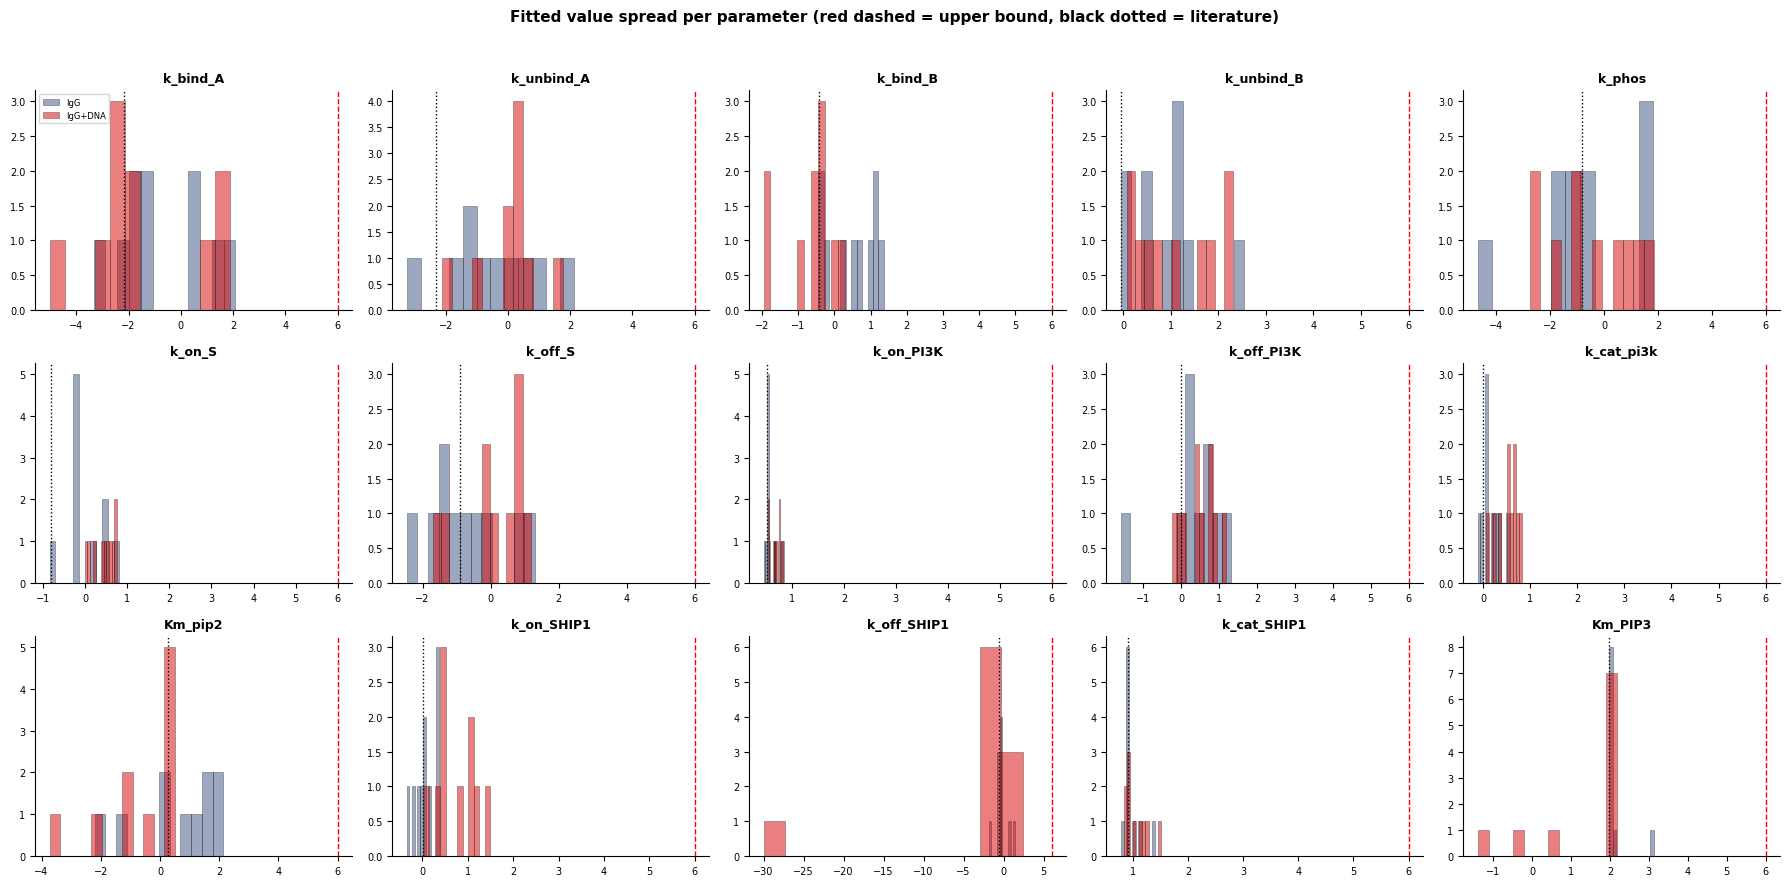

Saved: bounds_diagnostic.png
SUPP S1 complete.


In [7]:
# ============================================================================
# SUPP S1 — Bounds-hit diagnostic
# ============================================================================
REL_TOL_LOW, REL_TOL_HIGH, UPPER_BOUND = 1e-8, 0.99, 1e6
print('\n' + '='*70 + '\nSUPP S1 — BOUNDS-HIT DIAGNOSTIC\n' + '='*70)
any_hit = False
for cond in CONDITIONS:
    P = params_fitted[cond]
    for i, pname in enumerate(PNAMES):
        low  = int(np.sum(P[:, i] <= max(LOWER[i], REL_TOL_LOW) * (1 + 1e-6)))
        high = int(np.sum(P[:, i] >= REL_TOL_HIGH * UPPER_BOUND))
        if low or high:
            any_hit = True
            print(f'  {cond} {pname:<14} low={low} high={high}')
print('  No fit hit a bound.' if not any_hit else
      '  WARNING: some fits hit a bound; read affected composites with care.')

fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for i, pname in enumerate(PNAMES):
    ax = axes.flat[i]
    for cond, color in zip(CONDITIONS, [C_IgG, C_DNA]):
        vals = params_fitted[cond][:, i]
        ax.hist(np.log10(np.maximum(vals, 1e-30)), bins=12, color=color,
                alpha=0.5, edgecolor='k', linewidth=0.4, label=cond)
    ax.axvline(np.log10(UPPER_BOUND), color='red', ls='--', lw=1)
    ax.axvline(np.log10(params_g[i]), color='k', ls=':', lw=1)
    ax.set_title(pname, fontsize=9, fontweight='bold')
    ax.tick_params(labelsize=7); ax.spines[['top', 'right']].set_visible(False)
    if i == 0: ax.legend(fontsize=6)
fig.suptitle('Fitted value spread per parameter '
             '(red dashed = upper bound, black dotted = literature)',
             fontsize=11, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('bounds_diagnostic.png', dpi=300, bbox_inches='tight'); plt.show()
print('Saved: bounds_diagnostic.png\nSUPP S1 complete.')


SUPP S2 — MEDIAN-FIT FIM (anchor sensitivity)

  Median-anchored eigenvalue spectrum:
  EV   log10 eval   top-loading parameters
  ----------------------------------------------------------------------
  EV 1       5.29   k_on_SHIP1(-0.44), k_cat_SHIP1(-0.44), k_off_SHIP1(+0.43)
  EV 2       4.98   k_on_PI3K(+0.35), k_cat_pi3k(+0.35), k_on_S(+0.35)
  EV 3       2.92   k_phos(+0.54), k_bind_B(+0.52), k_unbind_B(-0.50)
  EV 4       1.96   Km_pip2(-0.87), k_bind_A(-0.30), k_bind_B(+0.19)
  EV 5      -0.04   k_off_S(+0.66), k_bind_A(+0.44), Km_pip2(-0.38)
  EV 6      -0.87   k_unbind_A(-0.50), k_off_S(-0.46), k_cat_pi3k(-0.36)
  EV 7      -1.29   Km_PIP3(-0.68), k_cat_SHIP1(-0.42), k_on_SHIP1(-0.42)
  EV 8      -2.65   k_off_PI3K(+0.73), k_off_SHIP1(+0.50), k_unbind_A(-0.20)
  EV 9      -3.29   k_off_SHIP1(-0.67), k_off_PI3K(+0.52), Km_PIP3(+0.37)
  EV 10     -4.92   k_unbind_A(+0.67), k_bind_A(+0.41), k_unbind_B(+0.38)
  EV 11     -5.96   k_unbind_B(+0.68), k_bind_B(+0.53), k_bind_A(-0.3

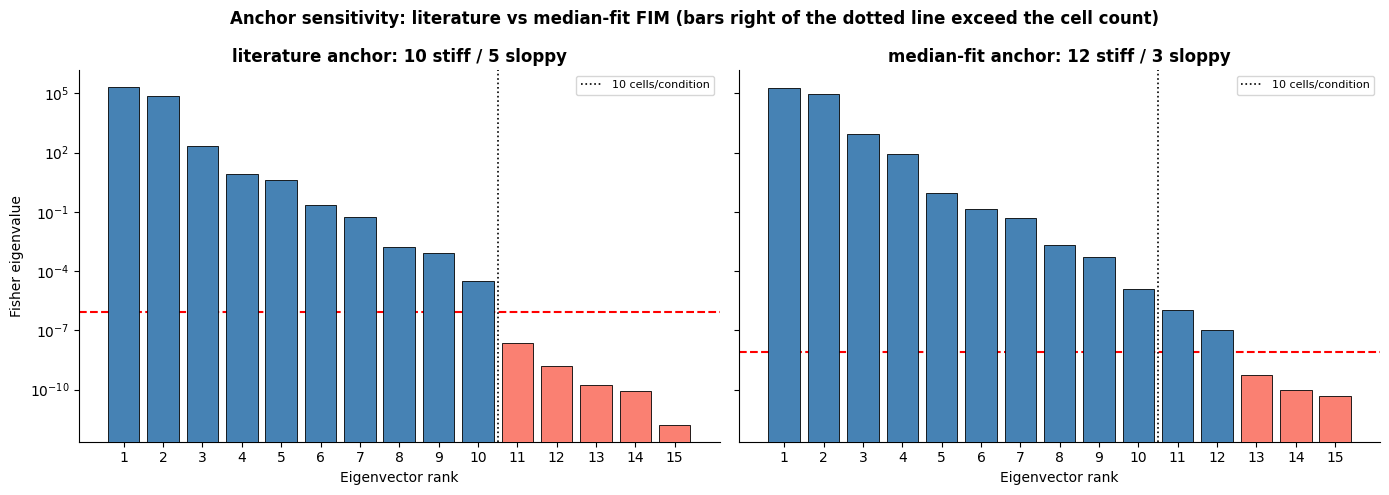


Saved: anchor_sensitivity_spectra.png
SUPP S2 complete.


In [8]:
# ============================================================================
# SUPP S2 — Anchor sensitivity: median-fit FIM (why we keep the literature anchor)
# ============================================================================
all_fits   = np.vstack([params_fitted[c] for c in CONDITIONS])
params_med = np.median(all_fits, axis=0)
n_cells_min = min(len(params_fitted[c]) for c in CONDITIONS)

fim_med   = fisher(params_med)
evals_med, evecs_med = fim_med['evals'], fim_med['evecs']
n_stiff_med, gap_med = fim_med['n_stiff'], fim_med['gap_idx']
log_evals_med = np.log10(np.maximum(evals_med, 1e-30))

print('\n' + '='*70 + '\nSUPP S2 — MEDIAN-FIT FIM (anchor sensitivity)\n' + '='*70)
print('\n  Median-anchored eigenvalue spectrum:')
print(f'  {"EV":<4}{"log10 eval":>11}   top-loading parameters')
print('  ' + '-'*70)
for i in range(NP):
    order = np.argsort(-np.abs(evecs_med[:, i]))[:3]
    ident = ', '.join(f'{PNAMES[j]}({evecs_med[j, i]:+.2f})' for j in order)
    mark = '  <-- biggest gap' if i == gap_med else ''
    print(f'  EV {i+1:<2}{log_evals_med[i]:>10.2f}   {ident}{mark}')

# metric 1: subspace overlap
n_common = min(n_stiff, n_stiff_med)
M = evecs[:, :n_common].T @ evecs_med[:, :n_common]
overlap_pct = 100 * np.linalg.norm(M, 'fro') / np.sqrt(n_common)

print('\n  WHY WE KEEP THE LITERATURE ANCHOR — metrics:')
print(f'    [1] stiff count:      literature = {n_stiff:>2}     median = {n_stiff_med:>2}')
print(f'    [2] cells/condition:  {n_cells_min}  '
      f'(median n_stiff {"exceeds" if n_stiff_med >= n_cells_min else "is below"} it '
      f'-> {"UNDER-DETERMINED" if n_stiff_med >= n_cells_min else "ok"})')
print(f'    [3] fraction of directions called stiff: '
      f'literature {n_stiff/NP*100:.0f}%   median {n_stiff_med/NP*100:.0f}%  '
      f'(higher = less filtering)')
print(f'    [4] stiff-subspace overlap (lit vs median) = {overlap_pct:.1f}% of maximum')

# metric 3: do composite CONCLUSIONS flip when we re-anchor?
Vs_med = evecs_med[:, :n_stiff_med]
D_med = {c: np.log(np.maximum(params_fitted[c], 1e-30)) - np.log(params_med)
         for c in CONDITIONS}
print(f'\n  Composite p-values under each anchor (does the call change?):')
print(f'    {"Composite":<21}{"lit p":>9}{"med p":>9}   change')
print('    ' + '-'*52)
n_flip = 0
for name in ordered_names:
    info = SUBSTAGE_COMPOSITES[name]; a = info['log_dir']
    a_med = Vs_med @ (Vs_med.T @ a)
    _, _, p_lit = composite_pvalues(V_stiff @ (V_stiff.T @ a), D, info['hypothesis'])
    _, _, p_med = composite_pvalues(a_med, D_med, info['hypothesis'])
    flip = (p_lit < 0.05) != (p_med < 0.05)
    n_flip += flip
    tag = '  <-- flips' if flip else ''
    print(f'    {name:<21}{p_lit:>9.4f}{p_med:>9.4f}{tag}')

print(f'\n  VERDICT: {n_flip} composite call(s) flip between anchors; the median '
      f'anchor keeps\n           {n_stiff_med}/{NP} directions "stiff" with only '
      f'{n_cells_min} cells/condition, so it barely\n           reduces dimensionality '
      f'and is under-determined. Keep the LITERATURE anchor.')

# side-by-side spectrum figure
fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (lbl, ev, ns, gi) in zip(
        axs, [('literature', evals, n_stiff, gap_idx),
              ('median-fit', evals_med, n_stiff_med, gap_med)]):
    cols = ['steelblue' if i < ns else 'salmon' for i in range(NP)]
    ax.bar(range(1, NP+1), np.maximum(ev, 1e-30), color=cols, edgecolor='k', lw=0.6, zorder=3)
    ax.set_yscale('log')
    ax.axhline(np.sqrt(max(ev[gi]*ev[gi+1], 1e-60)), color='red', ls='--', lw=1.5)
    ax.axvline(n_cells_min + 0.5, color='k', ls=':', lw=1.2, label=f'{n_cells_min} cells/condition')
    ax.set_title(f'{lbl} anchor: {ns} stiff / {NP-ns} sloppy', fontweight='bold')
    ax.set_xlabel('Eigenvector rank'); ax.set_xticks(range(1, NP+1))
    ax.legend(fontsize=8); ax.spines[['top', 'right']].set_visible(False)
axs[0].set_ylabel('Fisher eigenvalue')
fig.suptitle('Anchor sensitivity: literature vs median-fit FIM '
             '(bars right of the dotted line exceed the cell count)',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig('anchor_sensitivity_spectra.png', dpi=300,
                                bbox_inches='tight'); plt.show()
print('\nSaved: anchor_sensitivity_spectra.png\nSUPP S2 complete.')